In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
import glob
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
pnemonic_path=r"C:\Users\slava\chest_xray\test\PNEUMONIA"
normal_path=r"C:\Users\slava\chest_xray\test\NORMAL"

In [3]:
IMG_SIZE=(150,150)
BATCH_SIZE=32

In [4]:
pnemonic_images=glob.glob(pnemonic_path + r"\*.jpeg")
print("Number of pnemonic images: ",len(pnemonic_images))
normal_images=glob.glob(normal_path + r"\*.jpeg")
print("Number of normal images: ",len(normal_images))

Number of pnemonic images:  15
Number of normal images:  8


In [5]:
pnemonic_df=pd.DataFrame({"filename": pnemonic_images,"label":1})
normal_df=pd.DataFrame({"filename": normal_images,"label":0})
df=pd.concat([pnemonic_df,normal_df],ignore_index=True)

In [6]:
print("\n Dataset Shape: ")
print(df.shape)
print("\n First 5 Records: ")
print(df.head())
print("\n Last 5 Records: ")
print(df.tail())
print("\n Missing values: ")
print(df.isnull().sum())
print("\n Duplicates: ")
print(df.duplicated().sum())
df=df.drop_duplicates()


 Dataset Shape: 
(23, 2)

 First 5 Records: 
                                            filename  label
0  C:\Users\slava\chest_xray\test\PNEUMONIA\perso...      1
1  C:\Users\slava\chest_xray\test\PNEUMONIA\perso...      1
2  C:\Users\slava\chest_xray\test\PNEUMONIA\perso...      1
3  C:\Users\slava\chest_xray\test\PNEUMONIA\perso...      1
4  C:\Users\slava\chest_xray\test\PNEUMONIA\perso...      1

 Last 5 Records: 
                                             filename  label
18  C:\Users\slava\chest_xray\test\NORMAL\NORMAL2-...      0
19  C:\Users\slava\chest_xray\test\NORMAL\NORMAL2-...      0
20  C:\Users\slava\chest_xray\test\NORMAL\NORMAL2-...      0
21  C:\Users\slava\chest_xray\test\NORMAL\NORMAL2-...      0
22  C:\Users\slava\chest_xray\test\NORMAL\NORMAL2-...      0

 Missing values: 
filename    0
label       0
dtype: int64

 Duplicates: 
0


In [7]:
print("\n Class Distribution: ")
print(df["label"].value_counts())
print("\n Class Names:")
print(df["label"].value_counts().rename(index={0: "Normal", 1: "PNEUMONIA"}))


 Class Distribution: 
label
1    15
0     8
Name: count, dtype: int64

 Class Names:
label
PNEUMONIA    15
Normal        8
Name: count, dtype: int64


In [8]:
df = df.sample(frac=1,random_state=42
).reset_index(drop=True)

train_df, test_df = train_test_split(df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"])

print("\nTraining Images:",len(train_df))
print("Testing Images:",len(test_df))


Training Images: 18
Testing Images: 5


In [9]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.20)

In [10]:
test_datagen = ImageDataGenerator(
    rescale=1./255)

In [11]:
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filename",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="raw",
    subset="training",
    shuffle=True)

Found 15 validated image filenames.


In [12]:
validation_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filename",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="raw",
    subset="validation",
    shuffle=False)

Found 3 validated image filenames.


In [13]:
test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col="filename",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="raw",
    shuffle=False)


print("\nTraining Samples:",train_generator.samples)
print("Validation Samples:",validation_generator.samples)
print("Testing Samples:",test_generator.samples)

Found 5 validated image filenames.

Training Samples: 15
Validation Samples: 3
Testing Samples: 5


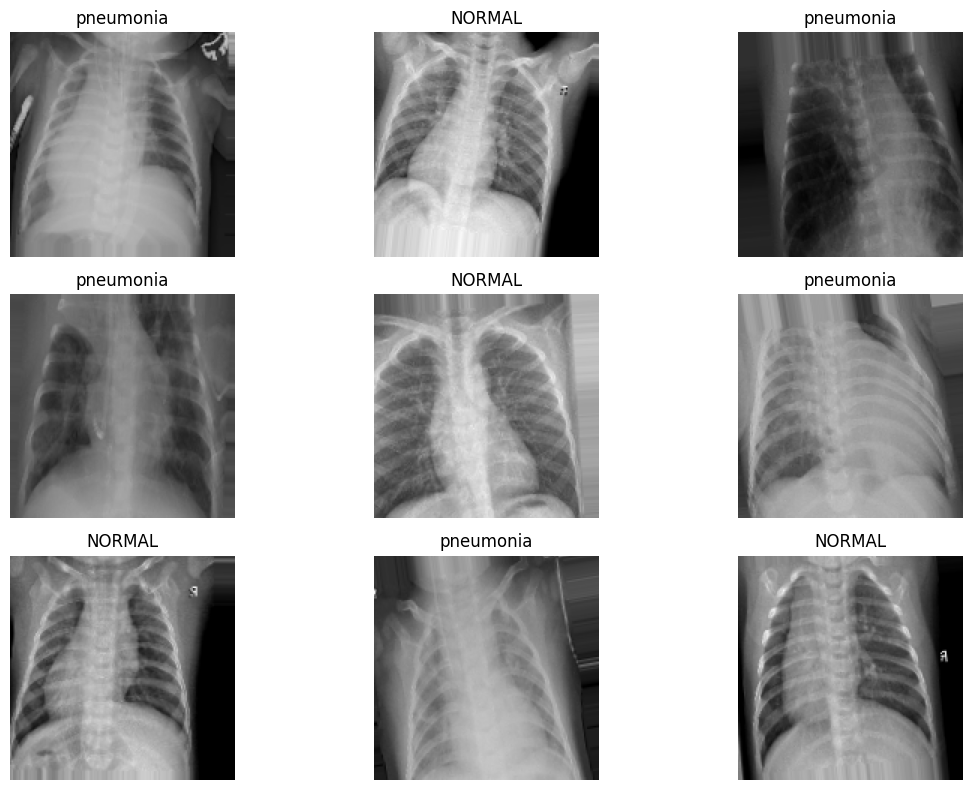

In [15]:

images,labels=next(train_generator)
plt.figure(figsize=(12, 8))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    if labels[i]==1:
        plt.title("pneumonia")
    else:
        plt.title("NORMAL")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [16]:
model = Sequential([

Conv2D(32,(3,3),activation="relu",
       input_shape=(150,150,3)),
MaxPooling2D(2,2),

Conv2D(64,(3,3),activation="relu"),
MaxPooling2D(2,2),

Conv2D(128,(3,3),activation="relu"),
MaxPooling2D(2,2),

Flatten(),

Dense(256,activation="relu"),

Dropout(0.5),
Dense(1,activation='sigmoid')])

C:\Users\slava\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
from tensorflow.keras.optimizers import Adam

model.summary()

model.compile(
    optimizer="adam",
    loss='binary_crossentropy',
    metrics=['accuracy']
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36992)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │       9,470,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,563,713 (36.48 MB)

 Trainable params: 9,563,713 (36.48 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history=model.fit(train_generator,
                 validation_data=validation_generator,
                 epochs=10)
test_loss, test_accuracy=model.evaluate(test_generator)
print("TEST RESULTS")
print("Test Loss: ",test_loss)
print("Test Accuracy: ",test_accuracy)

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.6667 - loss: 1.7515 - val_accuracy: 0.6667 - val_loss: 0.6706
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3333 - loss: 0.8575 - val_accuracy: 0.3333 - val_loss: 0.7688
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.4667 - loss: 0.7002 - val_accuracy: 0.6667 - val_loss: 0.6750
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5333 - loss: 0.6873 - val_accuracy: 0.6667 - val_loss: 0.6636
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6000 - loss: 0.6475 - val_accuracy: 0.6667 - val_loss: 0.6471
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.6667 - loss: 0.7135 - val_accuracy: 0.6667 - val_loss: 0.6285
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6667 - loss: 0.6968 - val_accuracy: 0.6667 - val_loss: 0.6338
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6667 - loss: 0.6307 - val_accuracy: 0.6667 - val_loss: 0.6547
Epoch 9/10
1/1 ━

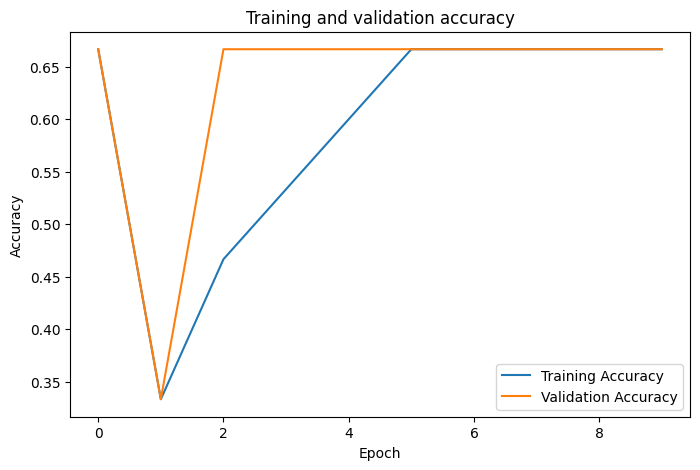

In [22]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')
plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.show()